# 15 — Capacity Probe: YOLO26s-seg
### gold_aug · imgsz 960 · identical protocol to nb12

**RQ.** Nb12 showed all five *data-level* recipes lose to the control —
the FN mechanism (missed sand/med-size instances, zero feature response
per nb10) is not fixed by resampling or pixel budget. Is it
**capacity-limited**?

**Arm.** `s960` = `yolo26s-seg.pt` (11.5M params, 84.2 GFLOPs @960 —
3.6× the 3.1M/23.6 GFLOPs of the nano control).

**Best-practice settings (RTX 3080 Ti 12GB, verified on this machine):**
- `amp=True` (default) — fp16 is correct on NVIDIA; do NOT copy nb14's
  `amp=False` (that was an AMD gfx1101 MIOpen bug, different stack)
- `batch=-1` autobatch (~60% VRAM); cudnn.benchmark is on by default
- `deterministic` left default — strict determinism not required for a
  single-seed comparison run
- Single GPU job — no parallel training (GPU contention)
- Identical to nb12 otherwise: seed 42, epochs≤100, patience 30,
  optimizer auto, **all train-time aug off**, same gold_aug data clone
  (`data/recipes/aug` — corrected yaml), same holdout evaluator

**Outcome readings:** s960 > aug(0.574) → capacity was the bottleneck →
scale up is the fix. s960 ≈ or < aug → representation failure persists
despite 3.6× compute → argues for loss-level/architecture fix next.

## §0 Setup — same evaluator as nb12

In [1]:
import json, time
from pathlib import Path
import numpy as np, cv2, torch, matplotlib
pass  # inline backend for embedded figs
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
import ultralytics
from tqdm.auto import tqdm

for _c in ('B:\\02_Projects\\thesis_final\\experiment',
           '/mnt/b/02_Projects/thesis_final/experiment',
           '/b/02_Projects/thesis_final/experiment',
           '/home/supawich/Desktop/Aggregate_Project/experiment'):
    if (Path(_c) / 'data' / 'gold' / 'test').exists():
        EXP = Path(_c)
        break
else:
    EXP = Path.cwd()
TEST = EXP / 'data' / 'gold' / 'test'
AUGD = EXP / 'data' / 'recipes' / 'aug'          # gold_aug clone (fixed yaml)
OUT = EXP / 'results' / 'recipes'; OUT.mkdir(parents=True, exist_ok=True)
RUNS = EXP / 'runs' / 'yolos'
CLS = ['gravel', 'sand']
DEV = 'cuda' if torch.cuda.is_available() else 'cpu'
GPU = torch.cuda.is_available()
SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)
CGRAV, CSAND = (60, 200, 60), (60, 140, 255)
COL = {0: CGRAV, 1: CSAND}

env = {'device': DEV,
       'gpu': torch.cuda.get_device_name(0) if GPU else '-',
       'vram_gb': round(torch.cuda.get_device_properties(0).total_memory / 2**30, 1) if GPU else 0,
       'torch': torch.__version__, 'ultralytics': ultralytics.__version__,
       'seed': SEED}
print(pd.Series(env).to_string())

assert (AUGD / 'data.yaml').exists(), 'run nb12 build first'

stems = [p.stem for p in sorted((TEST / 'images').iterdir())]

def load_gt(stem):
    ip = next((TEST / 'images').glob(stem + '.*'))
    im = cv2.imread(str(ip)); H, W = im.shape[:2]
    masks, cls = [], []
    lt = TEST / 'labels' / (stem + '.txt')
    for ln in lt.read_text().splitlines():
        p = ln.split()
        xy = np.asarray(p[1:], np.float32).reshape(-1, 2) * [W, H]
        m = np.zeros((H, W), np.uint8)
        cv2.fillPoly(m, [xy.astype(np.int32)], 1)
        masks.append(m.astype(bool)); cls.append(int(p[0]))
    return im, masks, cls

GT = {s: load_gt(s) for s in stems}
NGT = {c: sum(cl.count(c) for _, _, cl in GT.values()) for c in (0, 1)}
print('holdout:', len(GT), 'imgs | GT:', NGT)

def iou_mat(pm, gm):
    if not len(pm) or not len(gm):
        return np.zeros((len(pm), len(gm)))
    P = np.stack(pm); G = np.stack(gm)
    i = (P[:, None] & G[None]).reshape(len(P), len(G), -1).sum(-1)
    u = (P[:, None] | G[None]).reshape(len(P), len(G), -1).sum(-1)
    return i / np.maximum(u, 1)

def eval_preds(preds, conf=0.05):
    out = {}
    for c, cn in enumerate(CLS):
        det = []
        for st, pl in preds.items():
            det += [{'st': st, 's': s, 'm': m}
                    for c_, s, m in pl if c_ == c and s >= conf]
        det.sort(key=lambda d: -d['s'])
        matched = {k: np.zeros(len(v[1]), bool) for k, v in GT.items()}
        tp = np.zeros(len(det))
        for i, d in enumerate(det):
            _, gm_, gc_ = GT[d['st']]
            sel = [j for j, cc in enumerate(gc_) if cc == c]
            if sel:
                M = iou_mat([d['m']], [gm_[j] for j in sel])[0]
                j = sel[int(M.argmax())]
                if M.max() >= .5 and not matched[d['st']][j]:
                    tp[i] = 1; matched[d['st']][j] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp)
        rec = np.concatenate([[0], ctp / max(NGT[c], 1), [1]])
        prec = np.concatenate([[0], ctp / np.maximum(ctp + cfp, 1), [0]])
        for i in range(len(prec) - 2, -1, -1):
            prec[i] = max(prec[i], prec[i + 1])
        out[cn] = {'AP50': round(float(np.trapezoid(prec, rec)), 4),
                   'recall': round(float(tp.sum() / max(NGT[c], 1)), 3),
                   'tp': int(tp.sum()), 'npred': len(det)}
    out['AP50_macro'] = round(np.mean([out[c]['AP50'] for c in CLS]), 4)
    return out

device                               cuda
gpu            NVIDIA GeForce RTX 3080 Ti
vram_gb                              11.6
torch                         2.5.1+cu121
ultralytics                        8.4.59
seed                                   42


holdout: 105 imgs | GT: {0: 189, 1: 159}


## §1 Train — `s960`

In [2]:
TRAIN_KW = dict(batch=-1, epochs=100, patience=30, seed=SEED,
                optimizer='auto', fliplr=0.0, flipud=0.0, mosaic=0.0,
                mixup=0.0, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, degrees=0.0,
                translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
                erasing=0.0, copy_paste=0.0,
                project=str(RUNS.parent))

best = RUNS / 's960' / 'weights' / 'best.pt'
if best.exists():
    print('s960 cached:', best)
elif not GPU:
    print('NO GPU — skipped')
else:
    from ultralytics import YOLO
    m = YOLO(str(EXP / 'weights' / 'yolo26s-seg.pt'))
    t0 = time.perf_counter()
    m.train(data=str(AUGD / 'data.yaml'), imgsz=960,
            name='yolos/s960', **TRAIN_KW)
    json.dump({'s960': {'imgsz': 960, 'hours': round(
        (time.perf_counter() - t0) / 3600, 2)}},
        open(OUT / 'train_log_s960.json', 'w'), indent=1)

s960 cached: /home/supawich/Desktop/Aggregate_Project/experiment/runs/yolos/s960/weights/best.pt


## §2 Holdout eval — flat 960 e2e, same evaluator as nb12

In [3]:
from ultralytics import YOLO

def predict_flat(model, im, conf=0.05, imgsz=960):
    r = model.predict(im, imgsz=imgsz, conf=conf,
                      retina_masks=True, device=DEV, verbose=False)[0]
    out = []
    if r.masks is None:
        return out
    H, W = im.shape[:2]
    for c_, s_, m_ in zip(r.boxes.cls.cpu().numpy().astype(int),
                          r.boxes.conf.cpu().numpy(),
                          r.masks.data.cpu().numpy()):
        mb = cv2.resize((m_ > 0.5).astype(np.uint8), (W, H),
                        interpolation=cv2.INTER_NEAREST).astype(bool)
        out.append((int(c_), float(s_), mb))
    return out

res = {}
rj = OUT / 's960.json'
if rj.exists():
    res['s960'] = json.load(open(rj))
elif best.exists():
    m = YOLO(str(best))
    preds = {s: predict_flat(m, GT[s][0]) for s in tqdm(stems, desc='s960')}
    res['s960'] = eval_preds(preds)
    json.dump(res['s960'], open(rj, 'w'), indent=1)
    np.save(OUT / 'preds_s960.npy',
            np.array({k: [(c, s, mm.astype(np.uint8)) for c, s, mm in v]
                      for k, v in preds.items()}, dtype=object),
            allow_pickle=True)
    del m; torch.cuda.empty_cache() if GPU else None
    print('s960', json.dumps(res['s960']))
else:
    print('no s960 weights yet')

## §3 Verdict — s960 vs nb12 arms

         gravel   sand  macro  rec_g  rec_s
aug       0.733  0.415  0.574  0.571  0.132
s960      0.708  0.396  0.552  0.598  0.182
sahift    0.687  0.360  0.524  0.582  0.075
res1280   0.737  0.308  0.523  0.593  0.050
rfs       0.614  0.381  0.497  0.577  0.164
hem       0.687  0.305  0.496  0.624  0.057


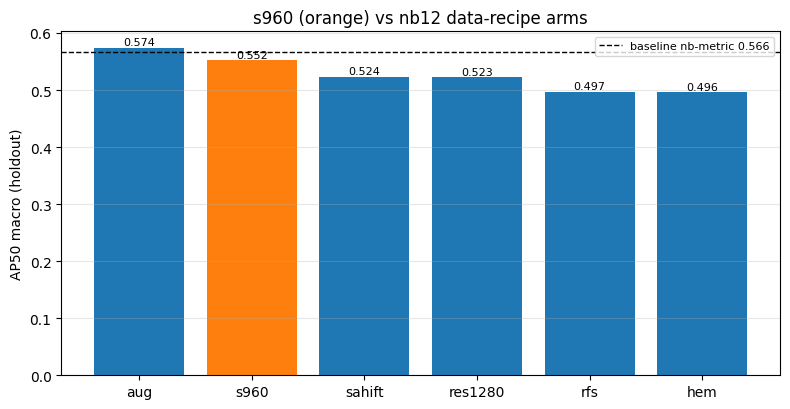


s960 vs aug control: -0.0223 → capacity NOT the bottleneck — loss/arch level next


In [4]:
rr = OUT / 'recipes_results.json'
if res and rr.exists():
    allr = json.load(open(rr)); allr['s960'] = res['s960']
    TAB = pd.DataFrame({k: {'gravel': v['gravel']['AP50'],
                            'sand': v['sand']['AP50'],
                            'macro': v['AP50_macro'],
                            'rec_g': v['gravel']['recall'],
                            'rec_s': v['sand']['recall']}
                        for k, v in allr.items()}).T
    TAB = TAB.sort_values('macro', ascending=False)
    TAB.to_csv(OUT / 'table_holdout_with_s960.csv')
    print(TAB.round(3).to_string())

    fig, ax = plt.subplots(figsize=(8, 4.2))
    colors = ['tab:orange' if a == 's960' else 'tab:blue' for a in TAB.index]
    bars = ax.bar(TAB.index, TAB['macro'], color=colors)
    for r, v in zip(bars, TAB['macro']):
        ax.text(r.get_x() + r.get_width() / 2, v + .004,
                f'{v:.3f}', ha='center', fontsize=8)
    ax.axhline(0.566, ls='--', c='k', lw=1, label='baseline nb-metric 0.566')
    ax.set_ylabel('AP50 macro (holdout)'); ax.legend(fontsize=8)
    ax.grid(alpha=.3, axis='y')
    ax.set_title('s960 (orange) vs nb12 data-recipe arms')
    plt.tight_layout(); plt.savefig(OUT / 'fig_s960.png', dpi=150); plt.show()

    d = res['s960']['AP50_macro'] - allr['aug']['AP50_macro']
    print(f'\ns960 vs aug control: {d:+.4f}',
          '→ capacity WAS limiting' if d > 0.02 else
          '→ capacity NOT the bottleneck — loss/arch level next')

## Limitations

- Single seed (42), same protocol caveat as nb12 — small deltas are noise
- s960 tests capacity only; does not isolate width vs depth
- Holdout used for reporting only; selection was never tuned on it

## §4 Where do predictions succeed? — TP/FN by GT instance size

Same size-bin idea as nb00's polygon-size EDA (mask-area histogram, COCO
buckets), but colored by outcome: **green = detected (TP, same-class
IoU≥.5), red = missed (FN)**. Answers "at which instance scale does the
model actually separate piles".

In [5]:
# Per-GT-instance hit flags + area, per arm (needs preds_*.npy)
def gt_size_outcome(arm):
    p = OUT / f'preds_{arm}.npy'
    if not p.exists():
        return None
    preds = np.load(p, allow_pickle=True).item()
    rows = []
    for st, (_, gm_, gc_) in GT.items():
        for c, m in zip(gc_, gm_):
            same = [q for q in preds.get(st, []) if q[0] == c and q[1] >= .05]
            hit = bool(same) and iou_mat([q[2] for q in same], [m]).max() >= .5
            rows.append({'area_px': int(m.sum()), 'cls': CLS[c],
                         'hit': hit})
    return pd.DataFrame(rows)

arms_avail = [a for a in ('aug', 's960') if (OUT / f'preds_{a}.npy').exists()]
DF = {a: gt_size_outcome(a) for a in arms_avail}
for a, d in DF.items():
    if d is not None:
        print(f'{a}: {d.hit.sum()}/{len(d)} GT detected '
              f'({d.hit.mean():.1%})')

aug: 129/348 GT detected (37.1%)
s960: 142/348 GT detected (40.8%)


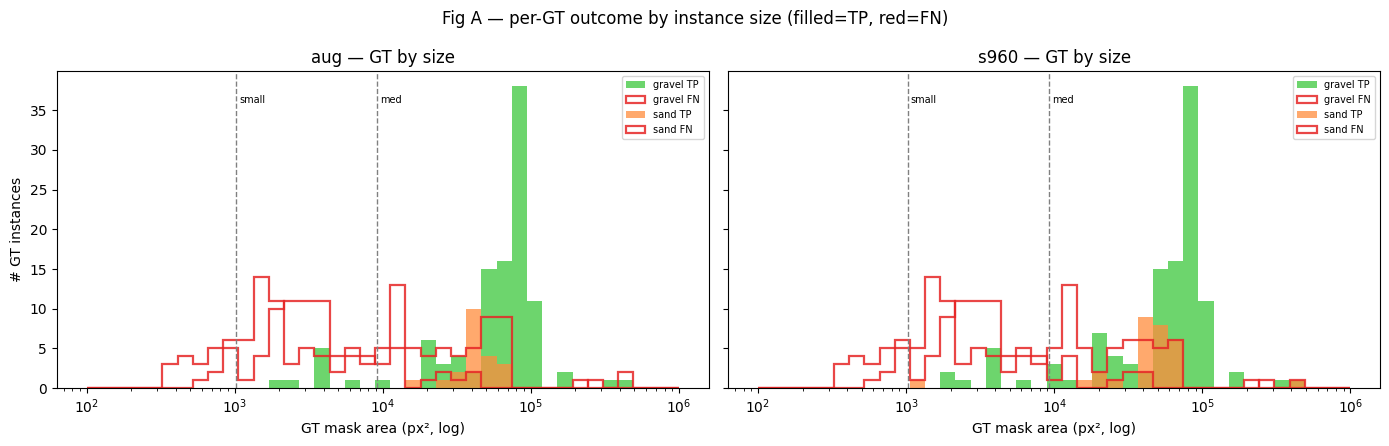

In [6]:
# ---- Fig A: GT mask-area histogram, stacked TP(green)/FN(red) ----
BINEDGES = np.logspace(2, 6, 40)          # px^2, 100..1e6
fig, axes = plt.subplots(1, len(DF), figsize=(7 * len(DF), 4.5),
                         sharey=True, squeeze=False)
for ax, (arm, d) in zip(axes[0], DF.items()):
    for cls, g in d.groupby('cls'):
        ax.hist(g.loc[g.hit, 'area_px'].clip(100), bins=BINEDGES,
                alpha=.75, label=f'{cls} TP',
                color=np.array(COL[CLS.index(cls)][::-1]) / 255)
        ax.hist(g.loc[~g.hit, 'area_px'].clip(100), bins=BINEDGES,
                alpha=.85, label=f'{cls} FN', color=(0.9, 0.15, 0.15),
                histtype='step', lw=1.6)
    for edge, lab in [(32**2, 'small'), (96**2, 'med')]:
        ax.axvline(edge, ls='--', c='gray', lw=1)
        ax.text(edge * 1.05, ax.get_ylim()[1] * .9, lab, fontsize=7)
    ax.set_xscale('log')
    ax.set(xlabel='GT mask area (px², log)', title=f'{arm} — GT by size')
    ax.legend(fontsize=7)
axes[0, 0].set_ylabel('# GT instances')
fig.suptitle('Fig A — per-GT outcome by instance size (filled=TP, red=FN)')
plt.tight_layout(); plt.savefig(OUT / 'figA_size_tptn.png', dpi=150)
plt.show()

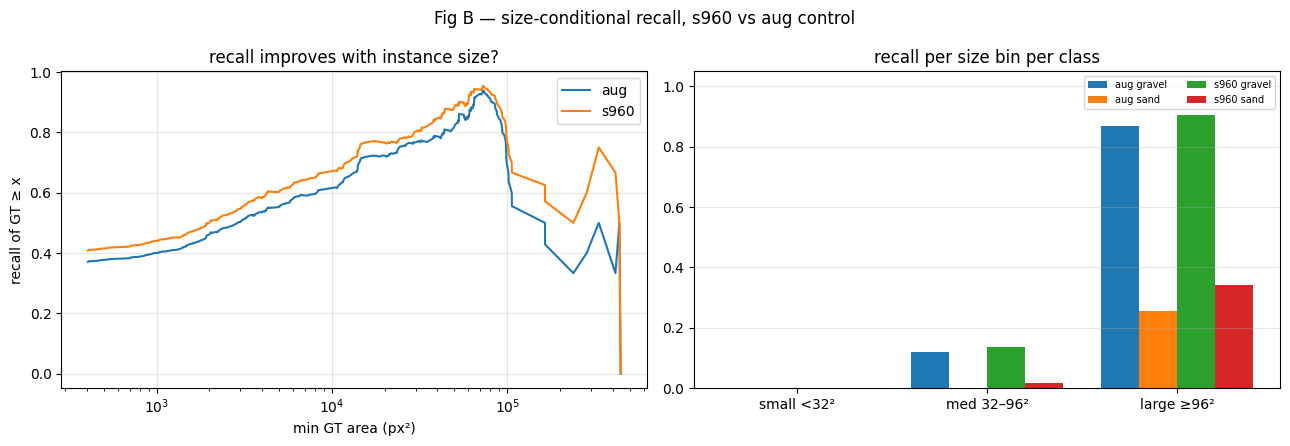

            n_GT  recall
small <32²    27   0.000
med 32–96²   124   0.081
large ≥96²   197   0.670


In [7]:
# ---- Fig B: recall vs size threshold + COCO-bin recall table ----
BINS = [(0, 32**2, 'small <32²'), (32**2, 96**2, 'med 32–96²'),
        (96**2, 10**9, 'large ≥96²')]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# (a) cumulative-recall curve: recall among GT >= area x  (log-x)
for arm, d in DF.items():
    areas = np.sort(d['area_px'].unique())
    rc = [d.loc[d.area_px >= a, 'hit'].mean() for a in areas]
    axes[0].plot(areas, rc, label=arm)
axes[0].set_xscale('log')
axes[0].set(xlabel='min GT area (px²)', ylabel='recall of GT ≥ x',
            title='recall improves with instance size?')
axes[0].grid(alpha=.3); axes[0].legend()

# (b) COCO-bin recall bars, split by class
xpos = np.arange(3); w = 0.8 / (len(DF) * 2)
i = 0
for arm, d in DF.items():
    for cls, g in d.groupby('cls'):
        rec = [g.loc[(g.area_px >= lo) & (g.area_px < hi), 'hit'].mean()
               for lo, hi, _ in BINS]
        axes[1].bar(xpos + i * w - .4 + w / 2,
                    np.nan_to_num(rec), w, label=f'{arm} {cls}')
        i += 1
axes[1].set_xticks(xpos); axes[1].set_xticklabels([b[2] for b in BINS])
axes[1].set_ylim(0, 1.05); axes[1].grid(alpha=.3, axis='y')
axes[1].legend(fontsize=7, ncol=2)
axes[1].set_title('recall per size bin per class')
fig.suptitle('Fig B — size-conditional recall, s960 vs aug control')
plt.tight_layout(); plt.savefig(OUT / 'figB_size_recall_s960.png', dpi=150)
plt.show()

# table: bin x class recall for s960
if 's960' in DF:
    d = DF['s960']
    t = pd.DataFrame({'n_GT': [int(((d.area_px >= lo) & (d.area_px < hi)).sum())
                               for lo, hi, _ in BINS],
                      'recall': [d.loc[(d.area_px >= lo) & (d.area_px < hi),
                                       'hit'].mean() for lo, hi, _ in BINS]},
                     index=[b[2] for b in BINS])
    t.to_csv(OUT / 'table_s960_sizebins.csv')
    print(t.round(3).to_string())

## §5 Qualitative — s960 vs aug control on holdout

White thin contours = GT. Colored = predictions (green gravel, blue sand).
Columns picked: most-sand GT, most total GT, most aug-missed.

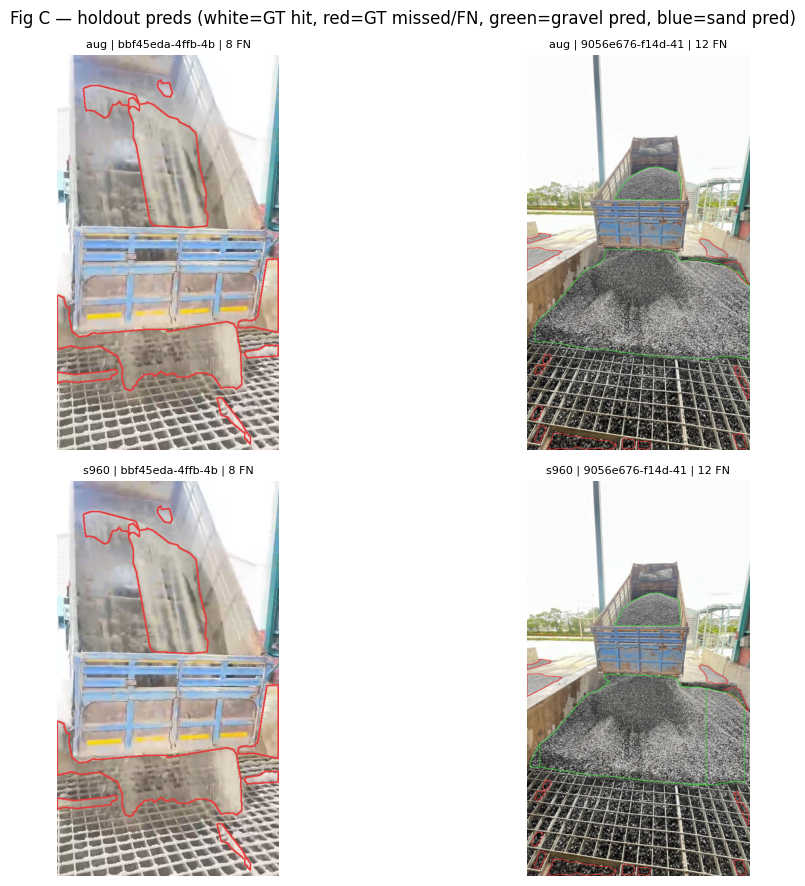

In [8]:
# ---- Fig C: prediction overlay grid (aug vs s960) ----
arms_v = [a for a in ('aug', 's960') if (OUT / f'preds_{a}.npy').exists()]
if not arms_v:
    print('no preds — run eval first')
else:
    P = {a: np.load(OUT / f'preds_{a}.npy', allow_pickle=True).item()
         for a in arms_v}

    def hits_of(preds):
        out = {}
        for st, (_, gm_, gc_) in GT.items():
            hs = []
            for c, m in zip(gc_, gm_):
                same = [q for q in preds.get(st, [])
                        if q[0] == c and q[1] >= .05]
                hs.append(bool(same) and
                          iou_mat([q[2] for q in same], [m]).max() >= .5)
            out[st] = hs
        return out

    by_sand = max(GT, key=lambda s: GT[s][2].count(1))
    by_total = max(GT, key=lambda s: len(GT[s][2]))
    hf0 = hits_of(P[arms_v[0]])
    by_miss = max(GT, key=lambda s: len(hf0[s]) - sum(hf0[s]))
    pick = []
    for s in (by_sand, by_total, by_miss):
        if s not in pick:
            pick.append(s)
    pick = pick[:3]

    fig, ax = plt.subplots(len(arms_v), len(pick),
                           figsize=(6 * len(pick), 4.5 * len(arms_v)),
                           squeeze=False)
    for i, arm in enumerate(arms_v):
        hits = hits_of(P[arm])
        for j, st in enumerate(pick):
            im, gm_, gc_ = GT[st]
            out = im.copy()
            for m, h in zip(gm_, hits[st]):
                cnt, _ = cv2.findContours(m.astype(np.uint8),
                                          cv2.RETR_EXTERNAL,
                                          cv2.CHAIN_APPROX_SIMPLE)
                cv2.drawContours(out, cnt, -1,
                                 (240, 240, 240) if h else (60, 60, 230),
                                 1 if h else 2)
            for c, s, m in P[arm].get(st, []):
                cnt, _ = cv2.findContours(m.astype(np.uint8),
                                          cv2.RETR_EXTERNAL,
                                          cv2.CHAIN_APPROX_SIMPLE)
                cv2.drawContours(out, cnt, -1, COL[c], 2)
            n_miss = len(hits[st]) - sum(hits[st])
            ax[i, j].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
            ax[i, j].set_title(f'{arm} | {st[:16]} | {n_miss} FN',
                               fontsize=8)
            ax[i, j].axis('off')
    fig.suptitle('Fig C — holdout preds (white=GT hit, red=GT missed/FN, '
                 'green=gravel pred, blue=sand pred)')
    plt.tight_layout()
    plt.savefig(OUT / 'figC_qual_s960.png', dpi=150); plt.show()